# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import os
# from random import randint
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40

In [2]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [3]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


ModuleNotFoundError: No module named 'plotnine'

## Helper functions

In [ ]:
# cyan_bumbl_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.bumbl"
# cyan_filelist_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan_filelist.txt"
# cyan_lengths_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.lengths"
# cyan_mums_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.mums"
# cyan_png_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/cyan.png"
# cyano_sa_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano/cyano.sa"
# cyan_dist_npy_path = "/vast/blangme2/sjhwang/match_based_pangenome_ani/data/cyano_vikram/dist.npy"


In [3]:
# Simulate a pairwise distance matrix between 10 genomes

# Set random seed for reproducibility
np.random.seed(42)

# Number of genomes
n_genomes = 10

# Generate genome names
genome_names = [f'genome_{i+1:02d}' for i in range(n_genomes)]

# Create a symmetric distance matrix
# Method 1: Generate random distances and ensure symmetry
# Start with random values
dist_matrix = np.random.uniform(0.1, 0.9, size=(n_genomes, n_genomes))

# Make it symmetric
dist_matrix = (dist_matrix + dist_matrix.T) / 2

# Set diagonal to 0 (distance from genome to itself)
np.fill_diagonal(dist_matrix, 0)

# Create a pandas DataFrame for easier viewing
simulated_dist_df = pd.DataFrame(dist_matrix, index=genome_names, columns=genome_names)

print(f"Simulated pairwise distance matrix for {n_genomes} genomes:")
print(f"Shape: {simulated_dist_df.shape}")
print("\nDistance matrix:")
print(simulated_dist_df.round(4))

Simulated pairwise distance matrix for 10 genomes:
Shape: (10, 10)

Distance matrix:
           genome_01  genome_02  genome_03  genome_04  genome_05  genome_06  \
genome_01     0.0000     0.4885     0.6375     0.5825     0.2112     0.5502   
genome_02     0.4885     0.0000     0.4888     0.2531     0.3708     0.4834   
genome_03     0.6375     0.4888     0.0000     0.2726     0.2962     0.7899   
genome_04     0.5825     0.2531     0.2726     0.0000     0.8500     0.7813   
genome_05     0.2112     0.3708     0.2962     0.8500     0.0000     0.6042   
genome_06     0.5502     0.4834     0.7899     0.7813     0.6042     0.0000   
genome_07     0.2787     0.3302     0.5114     0.3645     0.3371     0.3525   
genome_08     0.7554     0.3894     0.3079     0.4653     0.5908     0.4700   
genome_09     0.6857     0.5221     0.4693     0.3991     0.4431     0.2482   
genome_10     0.4311     0.5018     0.4229     0.5006     0.4823     0.4277   

           genome_07  genome_08  genome_09  g

## UPGMA code

In [4]:
# Build UPGMA tree from simulated distance matrix

from scipy.cluster.hierarchy import linkage, to_tree
from scipy.spatial.distance import squareform

# Convert distance DataFrame to condensed distance matrix (required by linkage)
# Extract the distance values as a numpy array
dist_matrix = simulated_dist_df.values

# Convert to condensed form (upper triangle as 1D array)
condensed_dist = squareform(dist_matrix)

# Build UPGMA tree using average linkage (UPGMA)
# method='average' implements UPGMA (Unweighted Pair Group Method with Arithmetic Mean)
linkage_matrix = linkage(condensed_dist, method='average')

# Convert linkage matrix to ete3 Tree
def linkage_to_ete3_tree(linkage_matrix, labels):
    """
    Convert scipy linkage matrix to ete3 Tree object.

    Parameters:
    -----------
    linkage_matrix : ndarray
        The linkage matrix from scipy.cluster.hierarchy.linkage
    labels : list
        List of leaf labels

    Returns:
    --------
    Tree : ete3.Tree
        The phylogenetic tree
    """
    # Convert to scipy tree structure
    scipy_tree = to_tree(linkage_matrix, rd=False)

    def build_newick(node, parent_dist, leaf_names):
        """Recursively build Newick string."""
        if node.is_leaf():
            return f"{leaf_names[node.id]}:{parent_dist - node.dist:.6f}"
        else:
            left = build_newick(node.left, node.dist, leaf_names)
            right = build_newick(node.right, node.dist, leaf_names)
            return f"({left},{right}):{parent_dist - node.dist:.6f}"

    # Build Newick string
    newick_str = build_newick(scipy_tree, scipy_tree.dist, labels) + ";"

    # Create ete3 Tree from Newick string
    tree = Tree(newick_str, format=1)
    return tree

# Build the tree
upgma_tree = linkage_to_ete3_tree(linkage_matrix, list(simulated_dist_df.index))

print("UPGMA tree built successfully!")
print(f"Number of leaves: {len(upgma_tree.get_leaves())}")
print("\nTree in Newick format:")
print(upgma_tree.write(format=1))

# Display the tree
print("\nTree visualization:")
print(upgma_tree.get_ascii(show_internal=True))


UPGMA tree built successfully!
Number of leaves: 10

Tree in Newick format:
((genome_07:0.307881,(genome_01:0.211223,genome_05:0.211223):0.096659):0.224582,((genome_10:0.363352,(genome_06:0.248164,genome_09:0.248164):0.115188):0.14966,((genome_02:0.253145,genome_04:0.253145):0.15085,(genome_03:0.307903,genome_08:0.307903):0.096093):0.109016):0.019452);

Tree visualization:

      /-genome_07
   /-|
  |  |   /-genome_01
  |   \-|
  |      \-genome_05
  |
--|      /-genome_10
  |   /-|
  |  |  |   /-genome_06
  |  |   \-|
  |  |      \-genome_09
   \-|
     |      /-genome_02
     |   /-|
     |  |   \-genome_04
      \-|
        |   /-genome_03
         \-|
            \-genome_08


## partial MUM distance correlation to true tree distance, Sina's simulation (n=-15)

In [5]:
sim_bwt_path = "/scratch4/blangme2/sjhwang/mem_ani/data/sim_phylo_tree_model/mumemto_out/sim_n15.bwt"
sim_lcp_path = "/scratch4/blangme2/sjhwang/mem_ani/data/sim_phylo_tree_model/mumemto_out/sim_n15.lcp"
sim_lengths_path = "/scratch4/blangme2/sjhwang/mem_ani/data/sim_phylo_tree_model/mumemto_out/sim_n15.lengths"
sim_mums_path = "/scratch4/blangme2/sjhwang/mem_ani/data/sim_phylo_tree_model/mumemto_out/sim_n15.mums"

sim_tree_path = "/scratch4/blangme2/sjhwang/mem_ani/data/sim_phylo_tree_model/RealTree.nwk"

In [6]:
# from the MUMs, get the powerset of lengths

from ete3 import Tree
from tqdm import tqdm as tqdm
import numpy as np
from matplotlib import pyplot as plt
from mumemto.utils import MUMdata
from mumemto.utils import get_sequence_lengths

# spearman rank correlation between the two
from scipy.stats import spearmanr

/home/shwang45/miniconda3/envs/mumemto_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
### parse mums
# note, reading the binary mum file is much faster that the mums themselves (ie. mum to bum conversion)
# `mumemto convert -m <file.mum>`
# mums = MUMdata(bum_path, verbose=True, sort=False) # then read with the new path as normal

mums = MUMdata(sim_mums_path, verbose=True, sort=False)


parsing MUM file: 2393617it [00:14, 166744.06it/s]


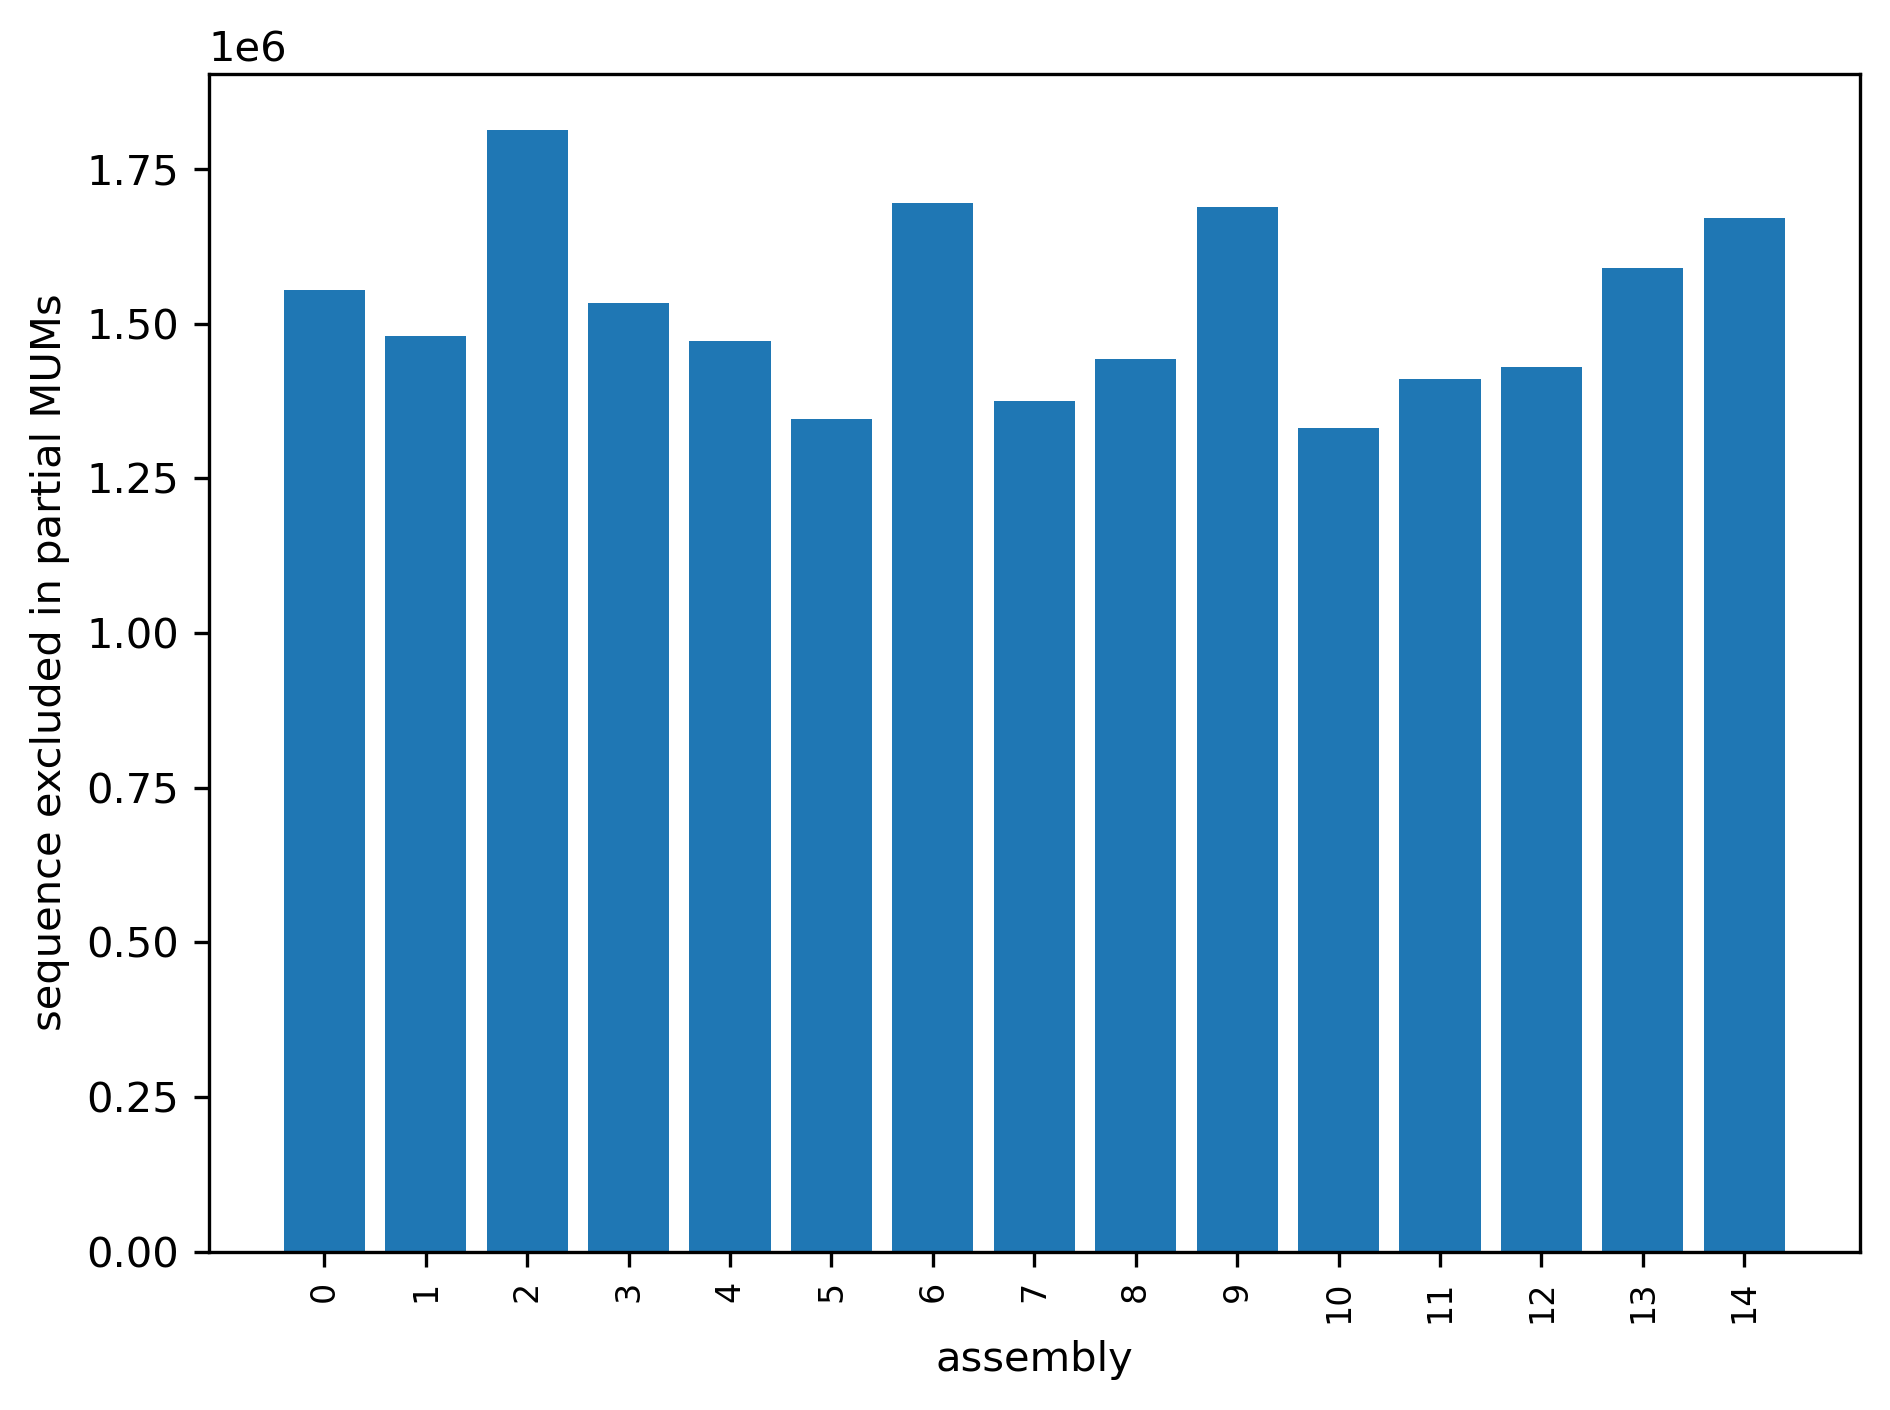

In [8]:
### count up which sequences are missing in partial MUMs, but weigh missing out on longer MUMs more
missing_mum, missing_seq = np.where(mums.starts == -1)
counts = np.bincount(missing_seq)
missing_lens = mums.lengths[missing_mum]

### plot
fig, ax = plt.subplots()
x = np.arange(mums.num_seqs)
# Label every bar with the sequence name, if possible:
if hasattr(mums, 'seq_names') and len(mums.seq_names) == mums.num_seqs:
    seq_labels = mums.seq_names
else:
    seq_labels = [str(i) for i in x]
bars = ax.bar(x, counts)
ax.set_xlabel('assembly')
ax.set_ylabel('sequence excluded in partial MUMs')
ax.set_xticks(x)
ax.set_xticklabels(seq_labels, rotation=90, fontsize=8)
fig.set_dpi(300)
plt.tight_layout()
plt.show()


In [9]:
# make matrix dist_M trackign the pairwise MUM overlap

num_genomes = mums.num_seqs
dist_M = np.zeros((num_genomes, num_genomes))

# for m in tqdm(range(mums.num_mums)):
for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]

    # For each pair of genomes that share this MUM
    for i in range(len(valid)):
        for j in range(i, len(valid)):
            dist_M[valid[i], valid[j]] += mum_length

dist_M

array([[31262081.,  8685142.,  6139664.,  7818464.,  8769082., 16263890.,
         6455945., 15703798., 14398267.,  6102531., 16413397.,  9305853.,
        14594101., 23252028.,  6238356.],
       [       0., 34802139.,  8270169., 13735753., 15770293., 11305845.,
        11275132., 10919705., 10156401., 10399205., 11398626., 33029698.,
        10275766.,  8307779., 10693188.],
       [       0.,        0., 17958688.,  7510425.,  8388135.,  7828025.,
         6212880.,  7632535.,  7146861.,  5889098.,  7947879.,  8859706.,
         7217960.,  5907425.,  6023615.],
       [       0.,        0.,        0., 29130067., 13928403., 10117642.,
         9964705.,  9774007.,  9097852., 13667166., 10225755., 14908337.,
         9197986.,  7495041., 14085721.],
       [       0.,        0.,        0.,        0., 31385223., 11394079.,
        12939534., 11081323., 10242345., 10547899., 11548264., 17200937.,
        10372127.,  8386483., 10853448.],
       [       0.,        0.,        0.,        0.

In [10]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    return tree1, dist_tree

In [11]:
# make tree distance dictionary

l = []
true_tree, dist_tree = dist_tree_calc(sim_tree_path)
species_pair_list = list(dist_tree.keys())
dist_tree_list = [dist_tree[pair] for pair in species_pair_list]
for pair, dist in list(zip(species_pair_list, dist_tree_list)):
    l.append([*pair ,dist])

tree_len = {}
for g1, g2, dist in l:
    if g1 not in tree_len:
        tree_len[g1] = {}
    if g2 not in tree_len:
        tree_len[g2] = {}
    tree_len[g1][g2] = dist
    tree_len[g2][g1] = dist


tree_len

{'SE001.fa': {'SE014.fa': 5.6999382,
  'SE006.fa': 15.976588,
  'SE009.fa': 17.52659903,
  'SE013.fa': 17.38767955,
  'SE008.fa': 16.3737954,
  'SE011.fa': 15.8051031,
  'SE002.fa': 29.913654469999997,
  'SE012.fa': 28.97576567,
  'SE005.fa': 29.91272807,
  'SE007.fa': 35.404460470000004,
  'SE004.fa': 32.0692547,
  'SE010.fa': 36.72317992,
  'SE015.fa': 36.39441977,
  'SE003.fa': 35.7663187},
 'SE014.fa': {'SE001.fa': 5.6999382,
  'SE006.fa': 16.6576624,
  'SE009.fa': 18.20767343,
  'SE013.fa': 18.06875395,
  'SE008.fa': 17.0548698,
  'SE011.fa': 16.4861775,
  'SE002.fa': 30.594728869999997,
  'SE012.fa': 29.65684007,
  'SE005.fa': 30.59380247,
  'SE007.fa': 36.085534870000004,
  'SE004.fa': 32.7503291,
  'SE010.fa': 37.40425432,
  'SE015.fa': 37.07549417,
  'SE003.fa': 36.4473931},
 'SE006.fa': {'SE001.fa': 15.976588,
  'SE014.fa': 16.6576624,
  'SE009.fa': 8.300270229999999,
  'SE013.fa': 8.16135075,
  'SE008.fa': 10.409867,
  'SE011.fa': 9.841174700000002,
  'SE002.fa': 25.56189327

In [12]:
# Correlation analysis between true tree distance and MUM distance matrix
# Extract pairwise distances from dist_M matrix and tree_len dictionary
mum_distances = []
tree_distances = []

genomes_ = sorted(list(tree_len.keys()))

# Get all pairs of genomes
for i in range(len(genomes_)):
    for j in range(i+1, len(genomes_)):
        # Get genome names
        genome_i = genomes_[i]
        genome_j = genomes_[j]

        # Get MUM distance from dist_M matrix
        mum_dist = dist_M[i, j]
        mum_distances.append(mum_dist)

        # Get true tree distance
        tree_dist = tree_len[genome_i][genome_j]
        tree_distances.append(tree_dist)

# Calculate Spearman correlation
corr, pval = spearmanr(tree_distances, mum_distances)

print(f"Spearman correlation between true tree distance and MUM distance: {corr:.4f}")
print(f"P-value: {pval:.2e}")
print(f"Number of genome pairs: {len(mum_distances)}")


Spearman correlation between true tree distance and MUM distance: -0.9852
P-value: 8.91e-81
Number of genome pairs: 105


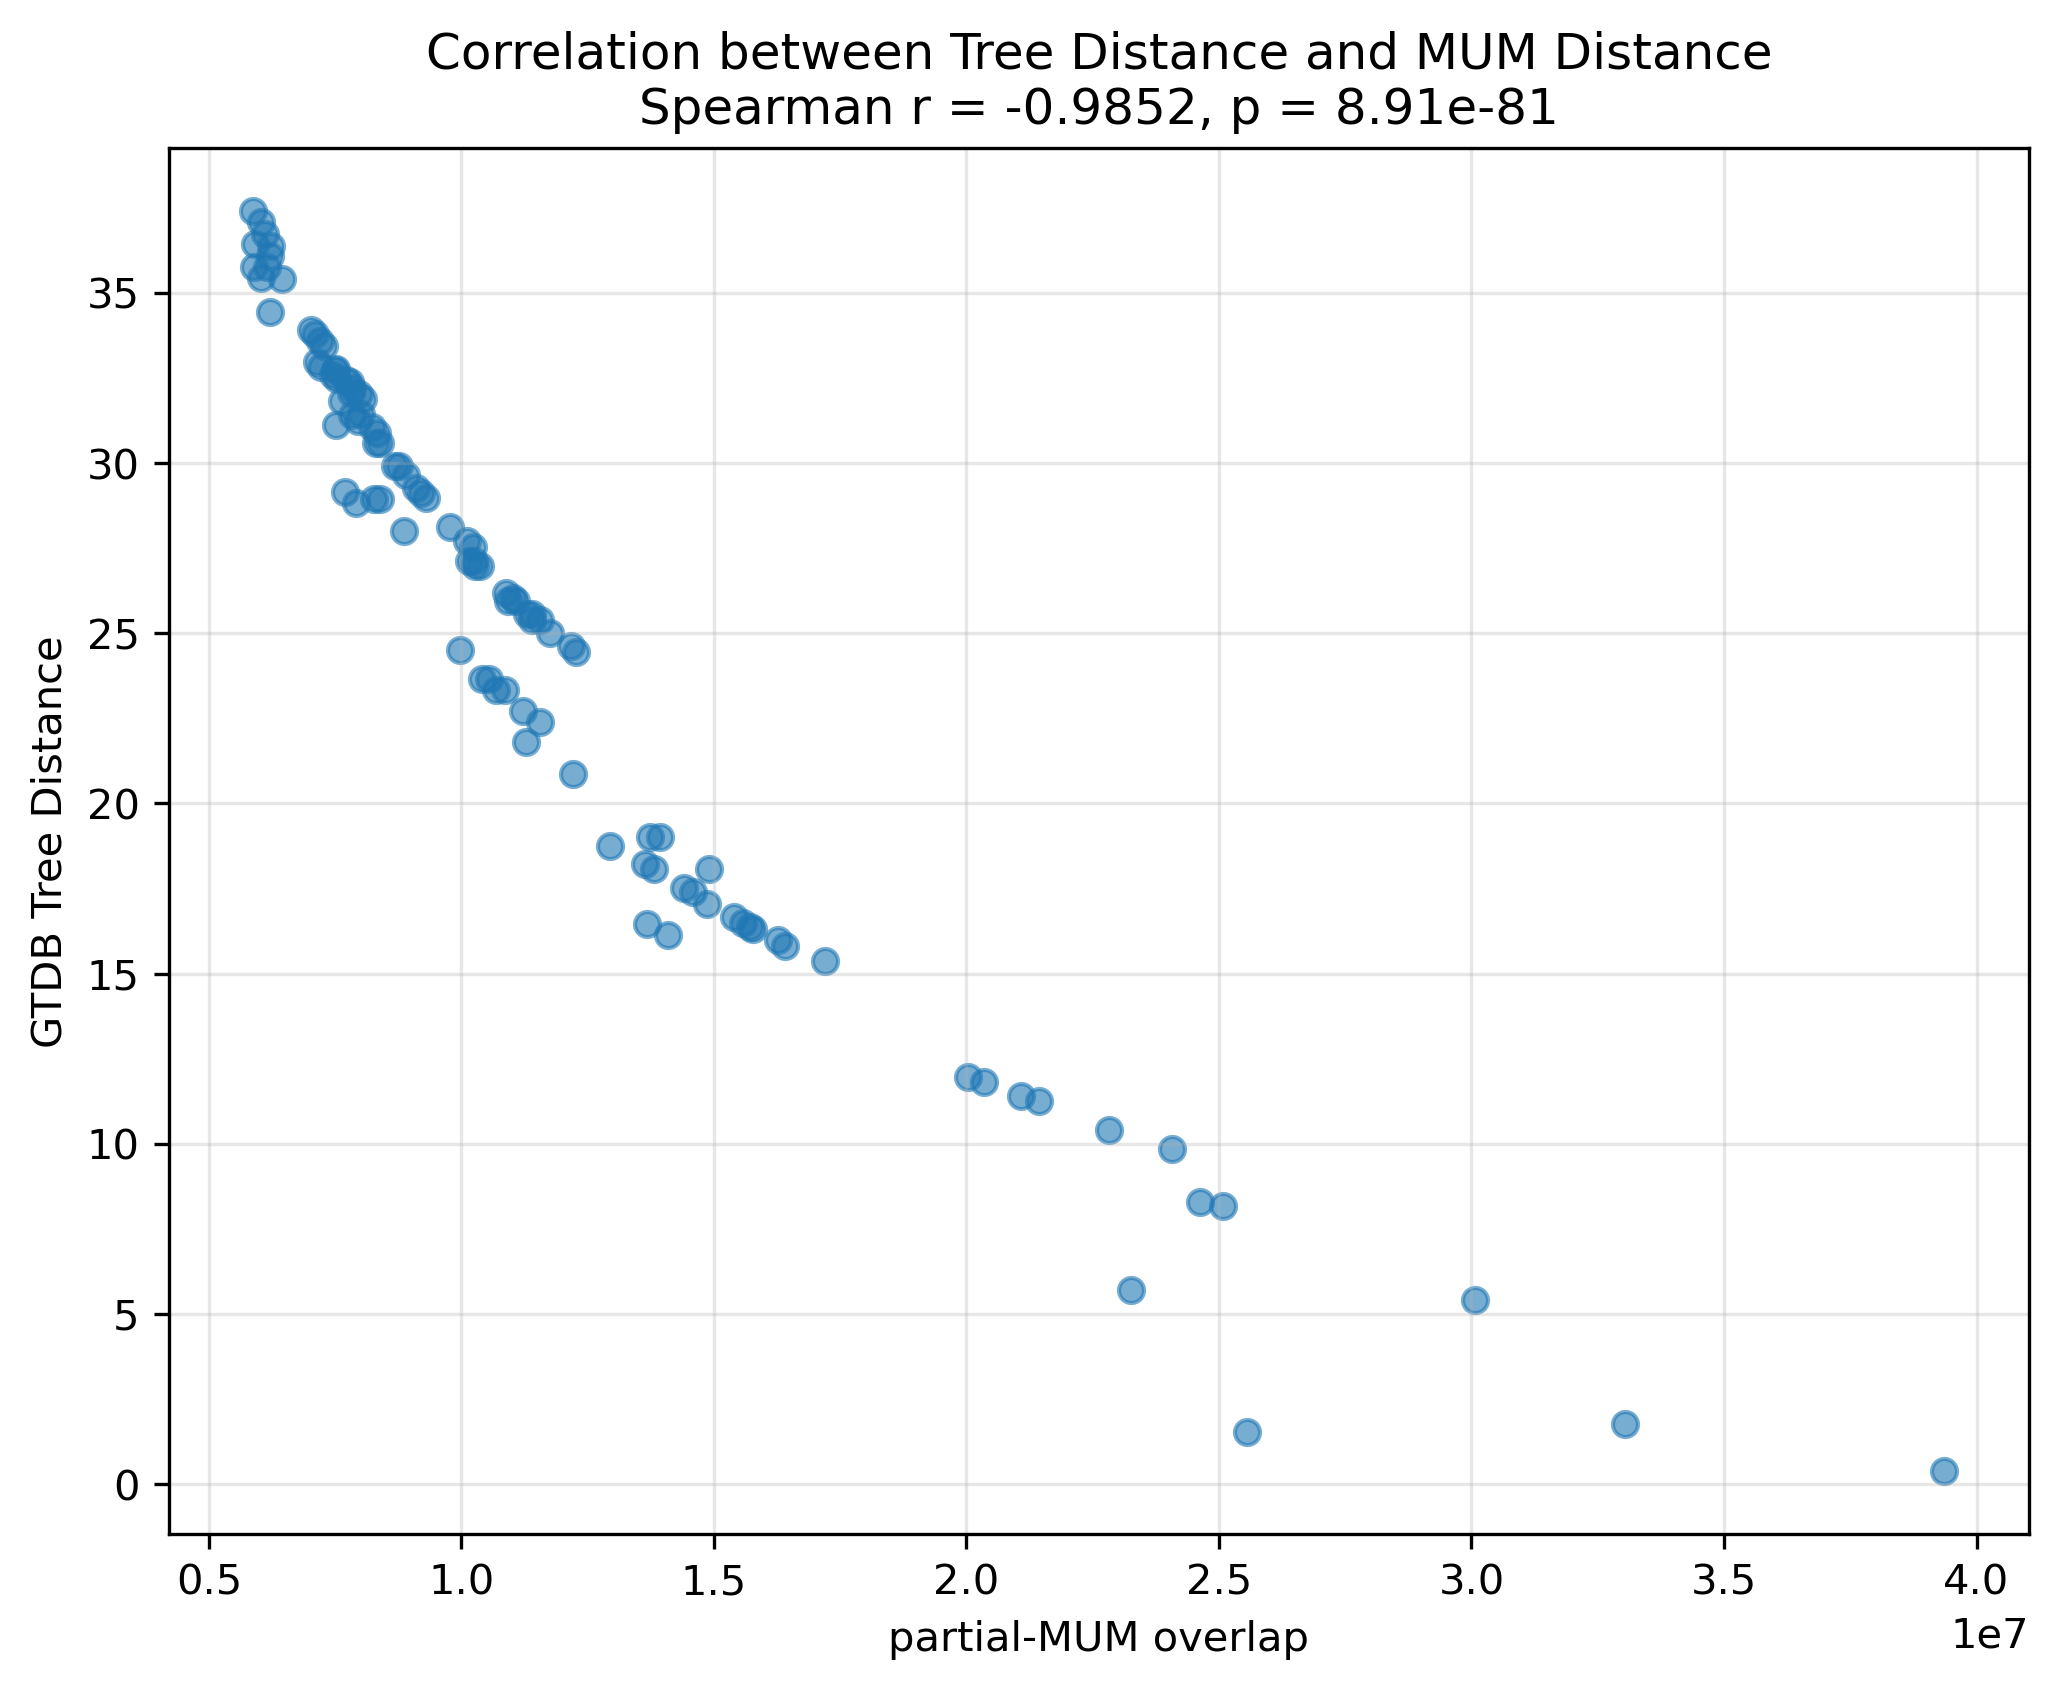

In [13]:
# plot correlation

plt.figure(figsize=(8, 6))
plt.scatter(mum_distances, tree_distances, alpha=0.6)
plt.ylabel('GTDB Tree Distance')
plt.xlabel('partial-MUM overlap')
plt.title(f'Correlation between Tree Distance and MUM Distance\nSpearman r = {corr:.4f}, p = {pval:.2e}')
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
# tree_distances
genomes_

['SE001.fa',
 'SE002.fa',
 'SE003.fa',
 'SE004.fa',
 'SE005.fa',
 'SE006.fa',
 'SE007.fa',
 'SE008.fa',
 'SE009.fa',
 'SE010.fa',
 'SE011.fa',
 'SE012.fa',
 'SE013.fa',
 'SE014.fa',
 'SE015.fa']

In [15]:
# The size of the powerset of a set with 15 items (excluding the empty set) is 2**15 = 32768
powerset_len = 2 ** 15
print(powerset_len)

################################################################################
from itertools import chain, combinations

def powerset(iterable):
    "powerset([1,2,3]) --> [()] [ (1,), (2,), (3,) ] [ (1,2), (1,3), (2,3) ] [ (1,2,3) ]"
    s = list(iterable)
    # chain.from_iterable: flatten the list of combinations for all possible subset lengths
    return list(chain.from_iterable(combinations(s, r) for r in range(len(s)+1)))

# Get all powersets of genome_names (as tuples)
all_powersets = powerset(genome_names)

# Optional: if you want as lists instead of tuples:
all_powersets_list = [list(subset) for subset in all_powersets]

# Example: print the number of subsets and a few examples
print(f"Total subsets: {len(all_powersets_list)}")
print("First 5 subsets:", all_powersets_list[:5])
print("Last 5 subsets:", all_powersets_list[-5:])




32768
Total subsets: 1024
First 5 subsets: [[], ['genome_01'], ['genome_02'], ['genome_03'], ['genome_04']]
Last 5 subsets: [['genome_01', 'genome_02', 'genome_03', 'genome_05', 'genome_06', 'genome_07', 'genome_08', 'genome_09', 'genome_10'], ['genome_01', 'genome_02', 'genome_04', 'genome_05', 'genome_06', 'genome_07', 'genome_08', 'genome_09', 'genome_10'], ['genome_01', 'genome_03', 'genome_04', 'genome_05', 'genome_06', 'genome_07', 'genome_08', 'genome_09', 'genome_10'], ['genome_02', 'genome_03', 'genome_04', 'genome_05', 'genome_06', 'genome_07', 'genome_08', 'genome_09', 'genome_10'], ['genome_01', 'genome_02', 'genome_03', 'genome_04', 'genome_05', 'genome_06', 'genome_07', 'genome_08', 'genome_09', 'genome_10']]


In [16]:
genome_names = sorted(tree_len.keys())
genome_names


['SE001.fa',
 'SE002.fa',
 'SE003.fa',
 'SE004.fa',
 'SE005.fa',
 'SE006.fa',
 'SE007.fa',
 'SE008.fa',
 'SE009.fa',
 'SE010.fa',
 'SE011.fa',
 'SE012.fa',
 'SE013.fa',
 'SE014.fa',
 'SE015.fa']

In [17]:
# Correlation analysis between true tree distance and MUM distance matrix
# Extract pairwise distances from dist_M matrix and tree_len dictionary
mum_distances = []
tree_distances = []

genomes_ = sorted(list(tree_len.keys()))

# Get all pairs of genomes
for i in range(len(genomes_)):
    for j in range(i+1, len(genomes_)):
        # Get genome names
        genome_i = genomes_[i]
        genome_j = genomes_[j]

        # Get MUM distance from dist_M matrix
        mum_dist = dist_M[i, j]
        mum_distances.append(mum_dist)

        # Get true tree distance
        tree_dist = tree_len[genome_i][genome_j]
        tree_distances.append(tree_dist)

# Calculate Spearman correlation
corr, pval = spearmanr(tree_distances, mum_distances)

print(f"Spearman correlation between true tree distance and MUM distance: {corr:.4f}")
print(f"P-value: {pval:.2e}")
print(f"Number of genome pairs: {len(mum_distances)}")


Spearman correlation between true tree distance and MUM distance: -0.9852
P-value: 8.91e-81
Number of genome pairs: 105


In [18]:
# Convert mum_distances (condensed distance vector) into a symmetric distance matrix

N = len(genomes_)
mum_dist_matrix = np.zeros((N, N))

idx = 0
for i in range(N):
    for j in range(i + 1, N):
        mum_dist_matrix[i, j] = mum_distances[idx]
        mum_dist_matrix[j, i] = mum_distances[idx]
        idx += 1

mum_dist_matrix

array([[       0.,  8685142.,  6139664.,  7818464.,  8769082., 16263890.,
         6455945., 15703798., 14398267.,  6102531., 16413397.,  9305853.,
        14594101., 23252028.,  6238356.],
       [ 8685142.,        0.,  8270169., 13735753., 15770293., 11305845.,
        11275132., 10919705., 10156401., 10399205., 11398626., 33029698.,
        10275766.,  8307779., 10693188.],
       [ 6139664.,  8270169.,        0.,  7510425.,  8388135.,  7828025.,
         6212880.,  7632535.,  7146861.,  5889098.,  7947879.,  8859706.,
         7217960.,  5907425.,  6023615.],
       [ 7818464., 13735753.,  7510425.,        0., 13928403., 10117642.,
         9964705.,  9774007.,  9097852., 13667166., 10225755., 14908337.,
         9197986.,  7495041., 14085721.],
       [ 8769082., 15770293.,  8388135., 13928403.,        0., 11394079.,
        12939534., 11081323., 10242345., 10547899., 11548264., 17200937.,
        10372127.,  8386483., 10853448.],
       [16263890., 11305845.,  7828025., 10117642.

In [19]:
# Build UPGMA tree from simulated distance matrix

def build_upgma_tree(dist_matrix, tree_labels):
    """
    Build a UPGMA tree from a full distance matrix and labels.
    Returns the ete3 tree object.
    """
    from scipy.spatial.distance import squareform
    from scipy.cluster.hierarchy import linkage

    # Convert to condensed form (upper triangle as 1D array)
    condensed_dist = squareform(dist_matrix)

    # Build UPGMA tree using average linkage (UPGMA)
    linkage_matrix = linkage(condensed_dist, method='average')

    # Build the tree
    upgma_tree = linkage_to_ete3_tree(linkage_matrix, tree_labels)

    print("UPGMA tree built successfully!")
    print(f"Number of leaves: {len(upgma_tree.get_leaves())}")
    print("\nTree in Newick format:")
    print(upgma_tree.write(format=1))

    # Display the tree
    print("\nTree visualization:")
    print(upgma_tree.get_ascii(show_internal=True))
    return upgma_tree

# Usage example:
# upgma_tree = build_upgma_tree(mum_dist_matrix, sorted(tree_len.keys()))

In [20]:
dist_matrix = mum_dist_matrix
tree_labels = [_.rstrip('.fa') for _ in genomes_]


upgma_tree = build_upgma_tree(dist_matrix, tree_labels)

UPGMA tree built successfully!
Number of leaves: 15

Tree in Newick format:
(SE011:1.47315e+07,((SE006:1.21731e+07,SE012:1.21731e+07):1.56272e+06,((SE004:9.19799e+06,SE013:9.19799e+06):3.05058e+06,(SE008:1.14956e+07,((SE002:9.68174e+06,(SE009:8.81588e+06,(SE007:6.70737e+06,(SE003:5.89826e+06,(SE010:5.87983e+06,SE014:5.87983e+06):18434.5):809111):2.10851e+06):865857):1.13549e+06,(SE005:9.81126e+06,(SE001:6.23836e+06,SE015:6.23836e+06):3.57291e+06):1.00596e+06):678408):752931):1.48729e+06):995683);

Tree visualization:

   /-SE011
  |
  |      /-SE006
--|   /-|
  |  |   \-SE012
  |  |
   \-|      /-SE004
     |   /-|
     |  |   \-SE013
     |  |
      \-|   /-SE008
        |  |
        |  |      /-SE002
        |  |   /-|
         \-|  |  |   /-SE009
           |  |   \-|
           |  |     |   /-SE007
           |  |      \-|
           |  |        |   /-SE003
            \-|         \-|
              |           |   /-SE010
              |            \-|
              |              

In [24]:

print(true_tree.get_ascii(show_internal=True))


         /-SE001
      /-|
     |   \-SE014
     |
   /-|      /-SE006
  |  |   /-|
  |  |  |  |   /-SE009
  |  |  |   \-|
  |   \-|      \-SE013
  |     |
  |     |   /-SE008
  |      \-|
  |         \-SE011
  |
--|            /-SE002
  |         /-|
  |        |   \-SE012
  |      /-|
  |     |  |   /-SE005
  |     |   \-|
  |   /-|      \-SE007
  |  |  |
  |  |  |   /-SE004
  |  |   \-|
   \-|     |   /-SE010
     |      \-|
     |         \-SE015
     |
      \-SE003


In [25]:

result = true_tree.robinson_foulds(upgma_tree)
rf_distance = result[0]
max_rf = result[1]

nrf = rf_distance / max_rf if max_rf > 0 else 0.0

print(f"Robinson-Foulds distance (rf): {rf_distance}")
print(f"Maximum possible RF distance (max_rf): {max_rf}")
print(f"Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: {nrf:.4f}")
result


Robinson-Foulds distance (rf): 26
Maximum possible RF distance (max_rf): 26
Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: 1.0000


[26,
 26,
 {'SE001',
  'SE002',
  'SE003',
  'SE004',
  'SE005',
  'SE006',
  'SE007',
  'SE008',
  'SE009',
  'SE010',
  'SE011',
  'SE012',
  'SE013',
  'SE014',
  'SE015'},
 {('SE001',),
  ('SE001',
   'SE002',
   'SE003',
   'SE004',
   'SE005',
   'SE006',
   'SE007',
   'SE008',
   'SE009',
   'SE010',
   'SE011',
   'SE012',
   'SE013',
   'SE014',
   'SE015'),
  ('SE001', 'SE006', 'SE008', 'SE009', 'SE011', 'SE013', 'SE014'),
  ('SE001', 'SE014'),
  ('SE002',),
  ('SE002', 'SE003', 'SE004', 'SE005', 'SE007', 'SE010', 'SE012', 'SE015'),
  ('SE002', 'SE004', 'SE005', 'SE007', 'SE010', 'SE012', 'SE015'),
  ('SE002', 'SE005', 'SE007', 'SE012'),
  ('SE002', 'SE012'),
  ('SE003',),
  ('SE004',),
  ('SE004', 'SE010', 'SE015'),
  ('SE005',),
  ('SE005', 'SE007'),
  ('SE006',),
  ('SE006', 'SE008', 'SE009', 'SE011', 'SE013'),
  ('SE006', 'SE009', 'SE013'),
  ('SE007',),
  ('SE008',),
  ('SE008', 'SE011'),
  ('SE009',),
  ('SE009', 'SE013'),
  ('SE010',),
  ('SE010', 'SE015'),
  ('SE011'

## MUM-informed bottom-up agglomerative tree building

In [26]:
num_genomes = mums.num_seqs
dist_M = np.zeros((num_genomes, num_genomes))

genome_partial_mum_tracker = dict()

for m in range(mums.num_mums):
    # Get MUM length and start positions for this MUM
    mum_length = mums.lengths[m]
    mum_starts = mums.starts[m]

    # Find valid positions (not -1)
    valid = np.where(mum_starts != -1)[0]
    key = frozenset(valid)
    genome_partial_mum_tracker[key] = genome_partial_mum_tracker.get(key, 0) + mum_length

genome_partial_mum_tracker

{frozenset({5, 10}): 1105540,
 frozenset({5, 7, 10}): 1418467,
 frozenset({5, 7, 8, 10, 12}): 1653642,
 frozenset({1, 4, 5, 6, 7, 8, 10, 11, 12}): 76599,
 frozenset({1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14}): 29452,
 frozenset({5, 10, 13}): 125160,
 frozenset({5, 7, 10, 13}): 222263,
 frozenset({5, 7, 8, 10, 12, 13}): 310145,
 frozenset({1, 4, 5, 6, 7, 8, 10, 11, 12, 13}): 16835,
 frozenset({1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14}): 6929,
 frozenset({2, 9, 14}): 239406,
 frozenset({2, 9, 10, 14}): 5144,
 frozenset({0, 5, 7, 10, 13}): 578055,
 frozenset({0, 5, 6, 7, 10, 13}): 26520,
 frozenset({1, 11}): 4834958,
 frozenset({9, 12, 14}): 4081,
 frozenset({0, 5, 13}): 476848,
 frozenset({0, 5, 8, 12, 13}): 524226,
 frozenset({1, 9, 11, 14}): 518421,
 frozenset({1, 2, 9, 11, 14}): 88679,
 frozenset({1, 2, 6, 9, 11, 14}): 43927,
 frozenset({1, 2, 3, 6, 9, 11, 14}): 80941,
 frozenset({0, 1, 2, 3, 5, 6, 8, 9, 11, 12, 13, 14}): 7123,
 frozenset({0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 12, 13, 14}): 5771,


In [27]:
print(len(genome_partial_mum_tracker), 32768)
17994 / 32768 * 100
# 54% of all possible powersets found


17994 32768


54.913330078125

In [28]:
def build_tree_from_powerset_similarity(genome_partial_mum_tracker, genome_names):
    """
    Build an ete3 tree from genome_partial_mum_tracker using bottom-up clustering.

    Parameters:
    -----------
    genome_partial_mum_tracker : dict
        Dictionary where keys are frozensets of genome indices and values are similarity values.
        Higher values = more similar.
    genome_names : list, optional
        List of genome names. If None, will use indices as names.

    Returns:
    --------
    tree : ete3.Tree
        The phylogenetic tree built from the similarity values.
    """

    # Extract all unique genome indices from the dictionary keys
    all_genomes = set()
    for key in genome_partial_mum_tracker.keys():
        all_genomes.update(key)
    all_genomes = sorted(list(all_genomes))

    # Create a mapping from index to name
    idx_to_name = {all_genomes[i]: genome_names[i] for i in range(len(all_genomes))}

    # Start with each genome as its own cluster
    clusters = [frozenset([g]) for g in all_genomes]
    cluster_to_node = {frozenset([g]): Tree(name=idx_to_name[g]) for g in all_genomes}

    # Find max similarity for normalization
    max_similarity = max(genome_partial_mum_tracker.values()) if genome_partial_mum_tracker else 1.0

    # Continue merging until we have one cluster
    iteration = 0
    while len(clusters) > 1:
        best_similarity = -1
        best_pair = None
        best_union = None

        # Find the two clusters with the highest similarity
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                cluster1 = clusters[i]
                cluster2 = clusters[j]
                union = cluster1 | cluster2

                # Look up similarity for the union in the dictionary
                similarity = genome_partial_mum_tracker.get(union, 0)

                if similarity > best_similarity:
                    best_similarity = similarity
                    best_pair = (i, j)
                    best_union = union

        if best_pair is None:  # If no similarity found, merge the first two clusters
            best_pair = (0, 1)
            best_union = clusters[0] | clusters[1]
            best_similarity = 0

        i, j = best_pair
        cluster1 = clusters[i]
        cluster2 = clusters[j]

        # Get the nodes for the clusters to merge
        node1 = cluster_to_node[cluster1]
        node2 = cluster_to_node[cluster2]

        # Create parent node
        parent = Tree()
        parent.add_child(node1)
        parent.add_child(node2)

        # Set branch lengths based on similarity (higher similarity = shorter distance)
        # Convert similarity to distance: higher similarity -> lower distance
        if best_similarity > 0 and max_similarity > 0:
            similarity_ratio = best_similarity / max_similarity # Normalize: similarity ratio (0 to 1), then convert to distance
            distance = (1.0 - similarity_ratio) * 0.1  # Scale factor can be adjusted; use a transformation: distance = (1 - normalized_similarity) * scale
        else:
            raise ValueError('no similarity found')  # distance = 0.1  # Default distance when no similarity found

        node1.dist = distance / 2
        node2.dist = distance / 2

        # Update cluster tracking
        new_cluster = best_union
        cluster_to_node[new_cluster] = parent

        # Remove old clusters and add new one (remove in reverse order to preserve indices)
        if i > j:
            clusters.pop(i)
            clusters.pop(j)
        else:
            clusters.pop(j)
            clusters.pop(i)
        clusters.append(new_cluster)

        iteration += 1

    # The final cluster should contain all genomes
    final_tree = cluster_to_node[clusters[0]]

    return final_tree


In [29]:
# Build the tree

tree_labels = [_.rstrip('.fa') for _ in genomes_]
powerset_tree = build_tree_from_powerset_similarity(genome_partial_mum_tracker, tree_labels)

print("Tree built successfully!")
print(f"Number of leaves: {len(powerset_tree.get_leaves())}")
print("\nTree in Newick format:")
print(powerset_tree.write(format=1))

# Display the tree
print("\nTree visualization:")
print(powerset_tree.get_ascii(show_internal=True))

Tree built successfully!
Number of leaves: 15

Tree in Newick format:
(((SE001:0.00966552,SE014:0.00966552):0.0386241,((SE008:0.0149003,SE011:0.0149003):0.0333833,(SE006:0.025029,(SE009:0,SE013:0):0.025029):0.0333833):0.0386241):0.0483339,(SE003:0.0480812,((SE004:0.0307847,(SE010:0.00087108,SE015:0.00087108):0.0307847):0.0459618,(SE007:0.0429638,(SE005:0.0355871,(SE002:0.00141561,SE012:0.00141561):0.0355871):0.0429638):0.0459618):0.0480812):0.0483339);

Tree visualization:

         /-SE001
      /-|
     |   \-SE014
     |
   /-|      /-SE008
  |  |   /-|
  |  |  |   \-SE011
  |   \-|
  |     |   /-SE006
  |      \-|
--|        |   /-SE009
  |         \-|
  |            \-SE013
  |
  |   /-SE003
  |  |
  |  |      /-SE004
   \-|   /-|
     |  |  |   /-SE010
     |  |   \-|
      \-|      \-SE015
        |
        |   /-SE007
         \-|
           |   /-SE005
            \-|
              |   /-SE002
               \-|
                  \-SE012


In [30]:
result = true_tree.robinson_foulds(powerset_tree)
rf_distance = result[0]
max_rf = result[1]

nrf = rf_distance / max_rf if max_rf > 0 else 0.0

print(f"Robinson-Foulds distance (rf): {rf_distance}")
print(f"Maximum possible RF distance (max_rf): {max_rf}")
print(f"Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: {nrf:.4f}")
# result


Robinson-Foulds distance (rf): 2
Maximum possible RF distance (max_rf): 26
Normalized Robinson-Foulds (nRF) distance between true tree and UPGMA tree: 0.0769


# Scratch

In [4]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [5]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

In [6]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    # print('num samples:', num_sample)
    # print('xxx:', num_sample * (num_sample-1)/2)
    # print('tree len:', len(dist_tree))
    return dist_tree


In [7]:
def make_tree_dict(tree_path):
    """
    Given a path to a Newick tree file, return a symmetric dictionary of distances between all pairs of taxa names
    (with or without '.fa' extension).

    Parameters:
        tree_path (str): Path to the Newick tree file.

    Returns:
        dict: A dictionary of dictionaries: { taxon_name: { other_taxon: distance, ... }, ... }
    """
    dist_tree = dist_tree_calc(tree_path)

    names = set()
    processed_pairs = []
    for (g1, g2), dist in dist_tree.items():
        g1_clean = g1.rstrip('.fa')
        g2_clean = g2.rstrip('.fa')
        names.add(g1_clean)
        names.add(g2_clean)
        processed_pairs.append((g1_clean, g2_clean, float(dist)))

    tree_dict = {name: {other: 0.0 for other in names} for name in names}
    for g1, g2, d in processed_pairs:
        tree_dict[g1][g2] = d
        tree_dict[g2][g1] = d  # Ensure symmetry

    return tree_dict


In [8]:

def get_random_samples(sample_names, sample_fraction=0.1, seed=None):
    '''
    # Example usage:
    cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
    '''
    if seed is not None:
        set_seed(seed)
    num_samples = max(1, int(len(sample_names) * sample_fraction))
    random_samples = sample(sample_names, num_samples)
    return random_samples



In [9]:
def parse_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('distance_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=1)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs

In [10]:
def build_merged_df(tree_dict, dashing_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_df['genome_pair'] = genome_pairs
    merged_df['genome_1'] = genomes_1s
    merged_df['genome_2'] = genomes_2s
    merged_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_df.shape}")

    # For each k, add a column to merged_df with the pairwise distances
    for fname, df in dashing_dfs.items():
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_df for this k
        colname = f'k{k_val}_distance'
        merged_df[colname] = merged_df.index.map(pair_to_dist.get)
        print(f"Added column '{colname}' to merged_df.")

    return merged_df

In [11]:
def process_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_dfs = parse_dashing_dfs(dashing_dir_path)
    merged_df = build_merged_df(tree_dict, dashing_dfs)
    return tree_dict, dashing_dfs, merged_df


In [12]:
# cyano_sample_names = sorted(cyano_nwk_dict.keys())
# chlam_sample_names = sorted(chlam_nwk_dict.keys())
# len(cyano_sample_names), len(chlam_sample_names)
# cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)

## Process data

In [13]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_data(caldisericia_tree_path, caldisericia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)

Error reading distance_k33.txt: No columns to parse from file

Loaded 28 files
distance_k10.txt: (288, 288)
distance_k11.txt: (288, 288)
distance_k12.txt: (288, 288)
distance_k13.txt: (288, 288)
distance_k14.txt: (288, 288)
distance_k15.txt: (288, 288)
distance_k16.txt: (288, 288)
distance_k17.txt: (288, 288)
distance_k18.txt: (288, 288)
distance_k19.txt: (288, 288)
distance_k20.txt: (288, 288)
distance_k21.txt: (288, 288)
distance_k22.txt: (288, 288)
distance_k23.txt: (288, 288)
distance_k24.txt: (288, 288)
distance_k25.txt: (288, 288)
distance_k26.txt: (288, 288)
distance_k27.txt: (288, 288)
distance_k28.txt: (288, 288)
distance_k29.txt: (288, 288)
distance_k30.txt: (288, 288)
distance_k31.txt: (288, 288)
distance_k32.txt: (288, 288)
distance_k5.txt: (288, 288)
distance_k6.txt: (288, 288)
distance_k7.txt: (288, 288)
distance_k8.txt: (288, 288)
distance_k9.txt: (288, 288)
Final dataframe shape: (41328, 4)
Added column 'k10_distance' to merged_df.
Added column 'k11_distance' to merged_

## Analyze corrrelation

In [14]:
# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict, sample_mask=[]):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')
                # Only analyze samples not in sample_mask
                if (g1 in sample_mask) or (g2 in sample_mask):
                    continue
                td = tree_dict[g1][g2]
                dashing_dist = float(df.loc[raw1, raw2])
                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        corr, pval = spearmanr(x_dashing, y_tree)
        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)


In [ ]:
# cyano_mask_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
# chlam_mask_samples = get_random_samples(chlam_sample_names, sample_fraction=0.1, seed=42)
# len(cyano_mask_samples), len(chlam_mask_samples)


NameError: name 'cyano_sample_names' is not defined

In [ ]:
# chlam_corr_df_mask = spearman_corr_against_tree(chlam_dashing_dfs, chlam_nwk_dict, chlam_mask_samples)

# Sort by numeric k when possible
# if 'k' in chlam_corr_df_mask.columns:
    # chlam_corr_df_mask = chlam_corr_df_mask.sort_values('k')

# chlam_corr_df_mask

NameError: name 'chlam_dashing_dfs' is not defined

## 2+ k-mer correlation

In [15]:
def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [16]:

def plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref=20):
    """
    Plot the Spearman correlations as a function of k (single and averaged k-mer ranks).

    Args:
        k_values (list): List of k values.
        combined_corrs (list): Spearman correlations for average of k_ref & k.
        single_k_corrs (list): Spearman correlations for single k.
        title (str, optional): Plot title. If None, generates a default title using k_ref.
        k_ref (int, optional): Reference k-mer value (default=20).
    """

    combined_label = f"(k, {k_ref})-mer average"
    single_label = "Single k-mer"

    plot_df = pd.DataFrame({
        'k_value': k_values,
        'Combined k': combined_corrs,
        single_label: single_k_corrs
    })

    plot_df = pd.melt(plot_df,
                      id_vars=['k_value'],
                      value_vars=['Combined k', single_label],
                      var_name='Method',
                      value_name='correlation')

    plot_df['Method'] = plot_df['Method'].replace({single_label: single_label, 'Combined k': combined_label})

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
        geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
        ggtitle(f"Dashing Jaccard index:\nSingle k-mer and (k, {k_ref})-mer average") +
        xlab("k-mer Jaccard length") +
        ylab("Spearman correlation") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
        scale_x_continuous(breaks=range(5,33,2)) +
        scale_color_manual(values=['#000000', '#D7263D'],
                          breaks=[single_label, combined_label])
    )
    return plot


In [17]:

# tree_dict =
# tree_dict =
# spearman_corr_against_tree(dfs_dict, tree_dict)

# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
spearman_corr_against_tree(chlamydia_dashing_dfs, chlamydia_tree_dict)


/tmp/ipykernel_2016425/2278004018.py:25: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


,k,spearman_corr,p_value,n_pairs
0,10,-0.344365,0.000000e+00,41328
1,11,-0.341808,0.000000e+00,41328
2,12,-0.291268,0.000000e+00,41328
3,13,-0.243907,0.000000e+00,41328
4,14,-0.228658,0.000000e+00,41328
5,15,-0.247307,0.000000e+00,41328
6,16,-0.304448,0.000000e+00,41328
7,17,-0.366936,0.000000e+00,41328
8,18,-0.398111,0.000000e+00,41328
9,19,-0.418595,0.000000e+00,41328


k=23,5: -0.698469637136924, 0.0
k=23,6: -0.698469637136924, 0.0
k=23,7: -0.6990298323382885, 0.0
k=23,8: -0.4598236967885044, 0.0
k=23,9: -0.47829313126756506, 0.0
k=23,10: -0.5264285489841093, 0.0
k=23,11: -0.5702784650543486, 0.0
k=23,12: -0.5727902362108572, 0.0
k=23,13: -0.5732296272037366, 0.0
k=23,14: -0.5824296986451096, 0.0
k=23,15: -0.6004681266193658, 0.0
k=23,16: -0.6257610294921394, 0.0
k=23,17: -0.6513948782865829, 0.0
k=23,18: -0.671771488724292, 0.0
k=23,19: -0.6843163027799688, 0.0
k=23,20: -0.6912551694310475, 0.0
k=23,21: -0.6956852281497259, 0.0
k=23,22: -0.6976278076953074, 0.0
k=23,23: -0.698469637136924, 0.0
k=23,24: -0.6986324780805152, 0.0


/tmp/ipykernel_2016425/2107416139.py:5: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


k=23,25: -0.6981524342843938, 0.0
k=23,26: -0.6972930986153184, 0.0
k=23,27: -0.6960448484671206, 0.0
k=23,28: -0.6948657187166338, 0.0
k=23,29: -0.693506947082278, 0.0
k=23,30: -0.6919559399073655, 0.0
k=23,31: -0.6904990361735708, 0.0
k=23,32: -0.6889560866213216, 0.0


/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 2 rows containing missing values.


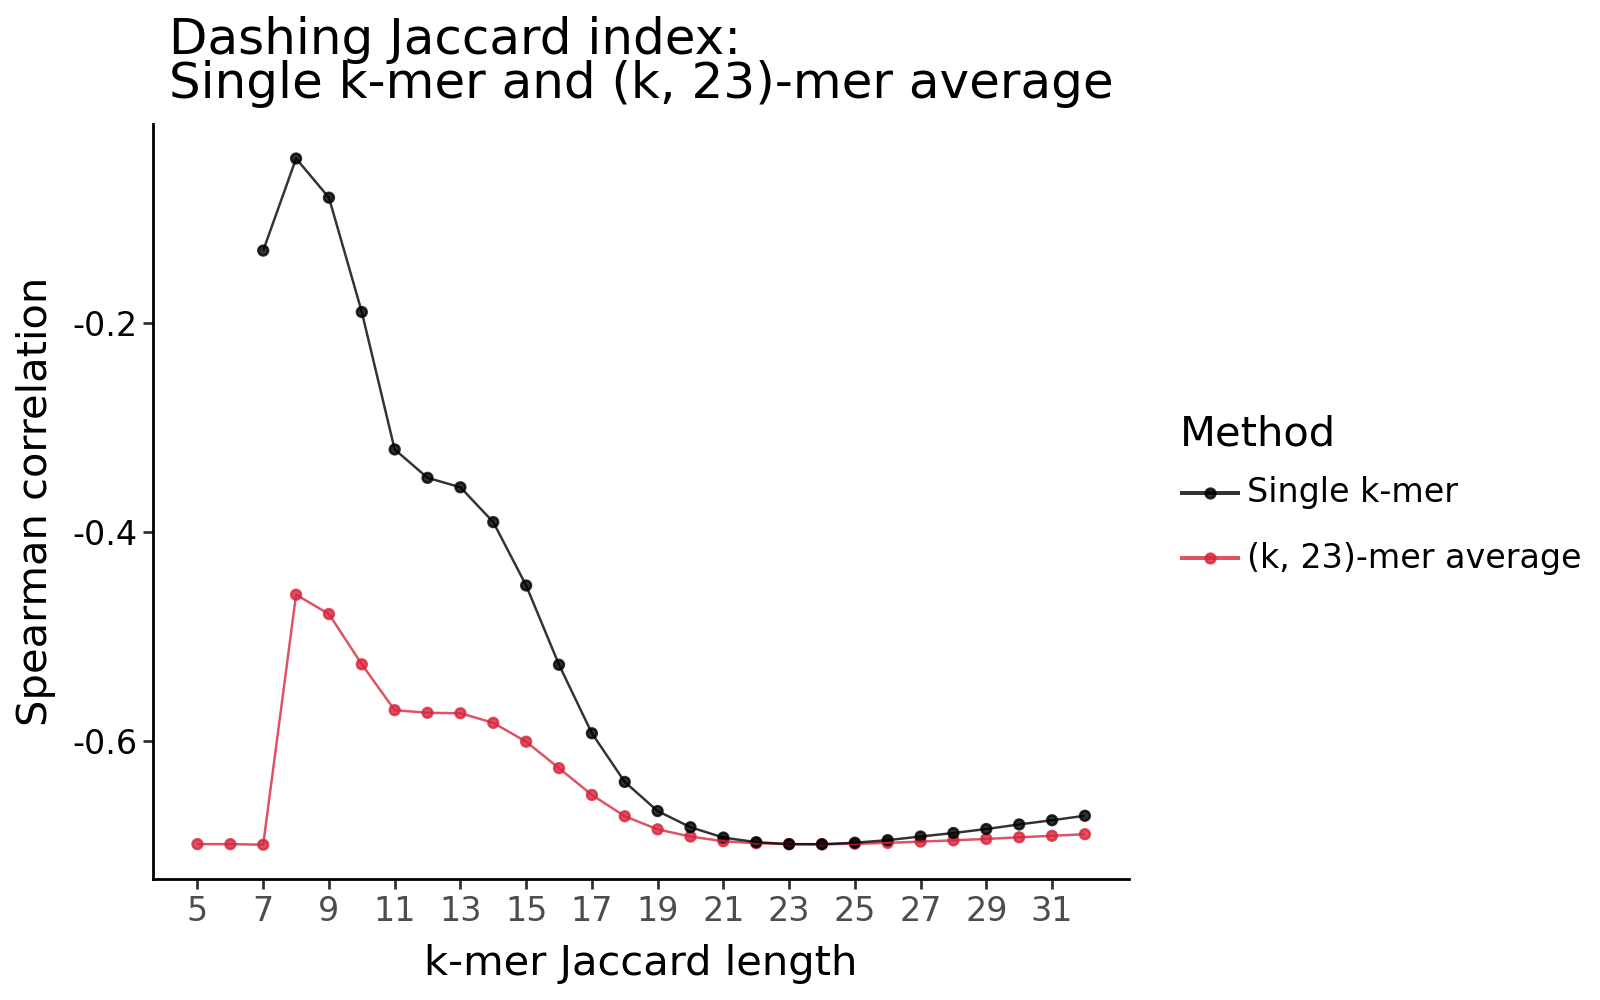

In [18]:
k_ref = 23
merged_df = bacillales_merged_df

k_values, combined_corrs, single_k_corrs = compute_kmer_avg_rank_corr(merged_df, k_ref)
plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref)

In [ ]:
# asdf



In [19]:
chlamydia_merged_df
aquificota_merged_df
bacillales_merged_df
caldisericia_merged_df
cyano_merged_df
neisseriaceae_merged_df

,genome_pair,genome_1,genome_2,tree_distance,k10_distance,k26_distance,k11_distance,k22_distance,k7_distance,k14_distance,...,k32_distance,k20_distance,k6_distance,k17_distance,k23_distance,k8_distance,k28_distance,k9_distance,k5_distance,k27_distance
GCA_000176735.1_GCA_000952795.1,GCA_000176735.1_GCA_000952795.1,GCA_000176735.1,GCA_000952795.1,0.087946,0.760883,0.031206,0.494572,0.040219,1.000000,0.105971,...,0.022050,0.046198,1.000000,0.059021,0.037662,0.997111,0.027692,0.947057,1,0.029320
GCA_000176735.1_GCA_001067655.1,GCA_000176735.1_GCA_001067655.1,GCA_000176735.1,GCA_001067655.1,0.085027,0.764904,0.029599,0.497369,0.037947,1.000000,0.102141,...,0.021108,0.043513,1.000000,0.055596,0.035577,0.997233,0.026344,0.949193,1,0.027854
GCA_000176735.1_GCA_002777825.1,GCA_000176735.1_GCA_002777825.1,GCA_000176735.1,GCA_002777825.1,0.427084,0.709826,0.000863,0.384369,0.001112,1.000000,0.019893,...,0.000663,0.001332,1.000000,0.002261,0.001034,0.996990,0.000782,0.941344,1,0.000819
GCA_000176735.1_GCA_003028315.1,GCA_000176735.1_GCA_003028315.1,GCA_000176735.1,GCA_003028315.1,0.089758,0.762226,0.030580,0.495143,0.039301,1.000000,0.104405,...,0.021710,0.045122,1.000000,0.057707,0.036826,0.997324,0.027180,0.947531,1,0.028752
GCA_000176735.1_GCA_016864895.1,GCA_000176735.1_GCA_016864895.1,GCA_000176735.1,GCA_016864895.1,0.659344,0.570616,0.000510,0.264123,0.000622,0.998901,0.011497,...,0.000387,0.000704,0.999519,0.001114,0.000591,0.987201,0.000463,0.877750,1,0.000486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GCF_946478525.1_GCF_962719845.1,GCF_946478525.1_GCF_962719845.1,GCF_946478525.1,GCF_962719845.1,0.429201,0.680859,0.000293,0.349719,0.000436,1.000000,0.015522,...,0.000194,0.000567,1.000000,0.001191,0.000389,0.995135,0.000252,0.931408,1,0.000269
GCF_946478525.1_GCF_962747995.1,GCF_946478525.1_GCF_962747995.1,GCF_946478525.1,GCF_962747995.1,0.433818,0.679830,0.000299,0.349573,0.000439,1.000000,0.015742,...,0.000205,0.000572,1.000000,0.001210,0.000393,0.995531,0.000260,0.931311,1,0.000277
GCF_946902045.1_GCF_962719845.1,GCF_946902045.1_GCF_962719845.1,GCF_946902045.1,GCF_962719845.1,0.078664,0.751149,0.026498,0.481637,0.033620,1.000000,0.091228,...,0.019341,0.038527,1.000000,0.049374,0.031586,0.995195,0.023741,0.940756,1,0.025012
GCF_946902045.1_GCF_962747995.1,GCF_946902045.1_GCF_962747995.1,GCF_946902045.1,GCF_962747995.1,0.083280,0.748799,0.022689,0.478153,0.029246,1.000000,0.085441,...,0.016165,0.033768,1.000000,0.043964,0.027368,0.995469,0.020171,0.939293,1,0.021327


# Scratch

In [27]:
# genomes =
from itertools import permutations

x = list(permutations(chlam_sample_names, 2))

In [ ]:
# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)



-0.4885741793163473 0.0


In [ ]:


# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)


In [ ]:
k_mid_ranks = merged_df[f'k_{k}'].rank()
avg_ranks = (k_mid_ranks + k20_ranks) / 2

In [ ]:
# for k=11, and 20 -0.4885741793163473 0.0

In [ ]:

# df_name = int(str(fname).replace('distance_k', '').replace('.txt', ''))
# g1, g2 = 'GCA_021372155.1', 'GCA_013813265.1'


# average of ranks of k
# g1

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_rank_dict = dict()

for g1, g2 in x[:10]:
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    d1_rank = df1.values.flatten().argsort().argsort()[df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)]
    d2_rank = df2.values.flatten().argsort().argsort()[df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)]
    d_avg = (d1_rank + d2_rank) / 2
    print(g1, g2, d_avg)





In [19]:
# 1. Find k indices where spearman_corr is a local minimum
from scipy.signal import argrelextrema
import numpy as np
from scipy.stats import spearmanr

# Assume chlam_corr_df is sorted by 'k'
corrs = chlam_corr_df['spearman_corr'].values
ks = chlam_corr_df['k'].values

# Find local minima (order=1 for adjacent points)
minima_idx = argrelextrema(corrs, np.less, order=1)[0]
local_minima_k = ks[minima_idx]

print("Local minima ks:", local_minima_k)

# 2. Calculate average ranks across the associated 'k's
# For each k in local_minima_k, get its index in chlam_corr_df
# Compute, for each sample: the average rank across all those ks
# We'll assume for the next step that there is a function or dataframe with per-sample values
# For demonstration, let's say chlam_dashing_dfs[k] is a dataframe for a given k, with index/sample and 'distance' column.

# Get list of "distance" values (distance matrices) for each minimum k
distance_matrices = [chlam_dashing_dfs[k] for k in local_minima_k]

# For a valid average-of-ranks, we'd usually compare all-against-all distances per sample.
# Let's flatten all off-diagonal distances for each matrix, then for each sample pair compute the mean rank
import pandas as pd

all_pairs = None
for k, df in zip(local_minima_k, distance_matrices):
    if isinstance(df, pd.DataFrame):
        mat = df.copy()
    else:
        mat = pd.DataFrame(df)
    dists = mat.values
    # Flatten and skip diagonal (self to self)
    mask = ~np.eye(dists.shape[0],dtype=bool)
    col = mat.columns if hasattr(mat, 'columns') else np.arange(dists.shape[0])
    row = mat.index if hasattr(mat, 'index') else np.arange(dists.shape[0])
    pairs = [(row[i], col[j], dists[i,j]) for i in range(dists.shape[0]) for j in range(dists.shape[1]) if i != j]
    tmp = pd.DataFrame(pairs, columns=['sample1', 'sample2', f'dist_{k}'])
    if all_pairs is None:
        all_pairs = tmp.set_index(['sample1', 'sample2'])
    else:
        all_pairs = all_pairs.join(tmp.set_index(['sample1', 'sample2']), how='inner')

# Now for each pair, take the average of the distances across used ks
all_pairs['avg_dist'] = all_pairs.mean(axis=1)
# Rank (average rank for each pair)
all_pairs['avg_dist_rank'] = all_pairs['avg_dist'].rank()

# Now, compare these ranks to the tree distances

# Create matching tree distances Series for sample pairs (assume chlam_nwk_dict has tree distances)
# We'll flatten the tree distances for each sample pair (match above order)

tree_dist_pairs = []
for i, name1 in enumerate(all_pairs.index.get_level_values(0)):
    name2 = all_pairs.index.get_level_values(1)[i]
    try:
        tree_dist = chlam_nwk_dict[name1][name2]
    except KeyError:
        tree_dist = chlam_nwk_dict[name2][name1]  # Try reverse
    tree_dist_pairs.append(tree_dist)
all_pairs['tree_dist'] = tree_dist_pairs
all_pairs['tree_dist_rank'] = all_pairs['tree_dist'].rank()

# Calculate Spearman's rank correlation between the average-of-ranks distances and tree ranks
spearman_corr, p_value = spearmanr(all_pairs['avg_dist_rank'], all_pairs['tree_dist_rank'])

print("Spearman correlation of average-of-ranks distances (at local minima ks) vs. tree distances:", spearman_corr)
print("p-value:", p_value)

Local minima ks: [10 20]


KeyError: 10

In [23]:
chlam_corr_df.loc[chlam_corr_df['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.424038
p_value              0.000000
n_pairs          41328.000000
Name: 10, dtype: float64

In [24]:
chlam_corr_df_mask.loc[chlam_corr_df_mask['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.422647
p_value              0.000000
n_pairs          33670.000000
Name: 10, dtype: float64

/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.
/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


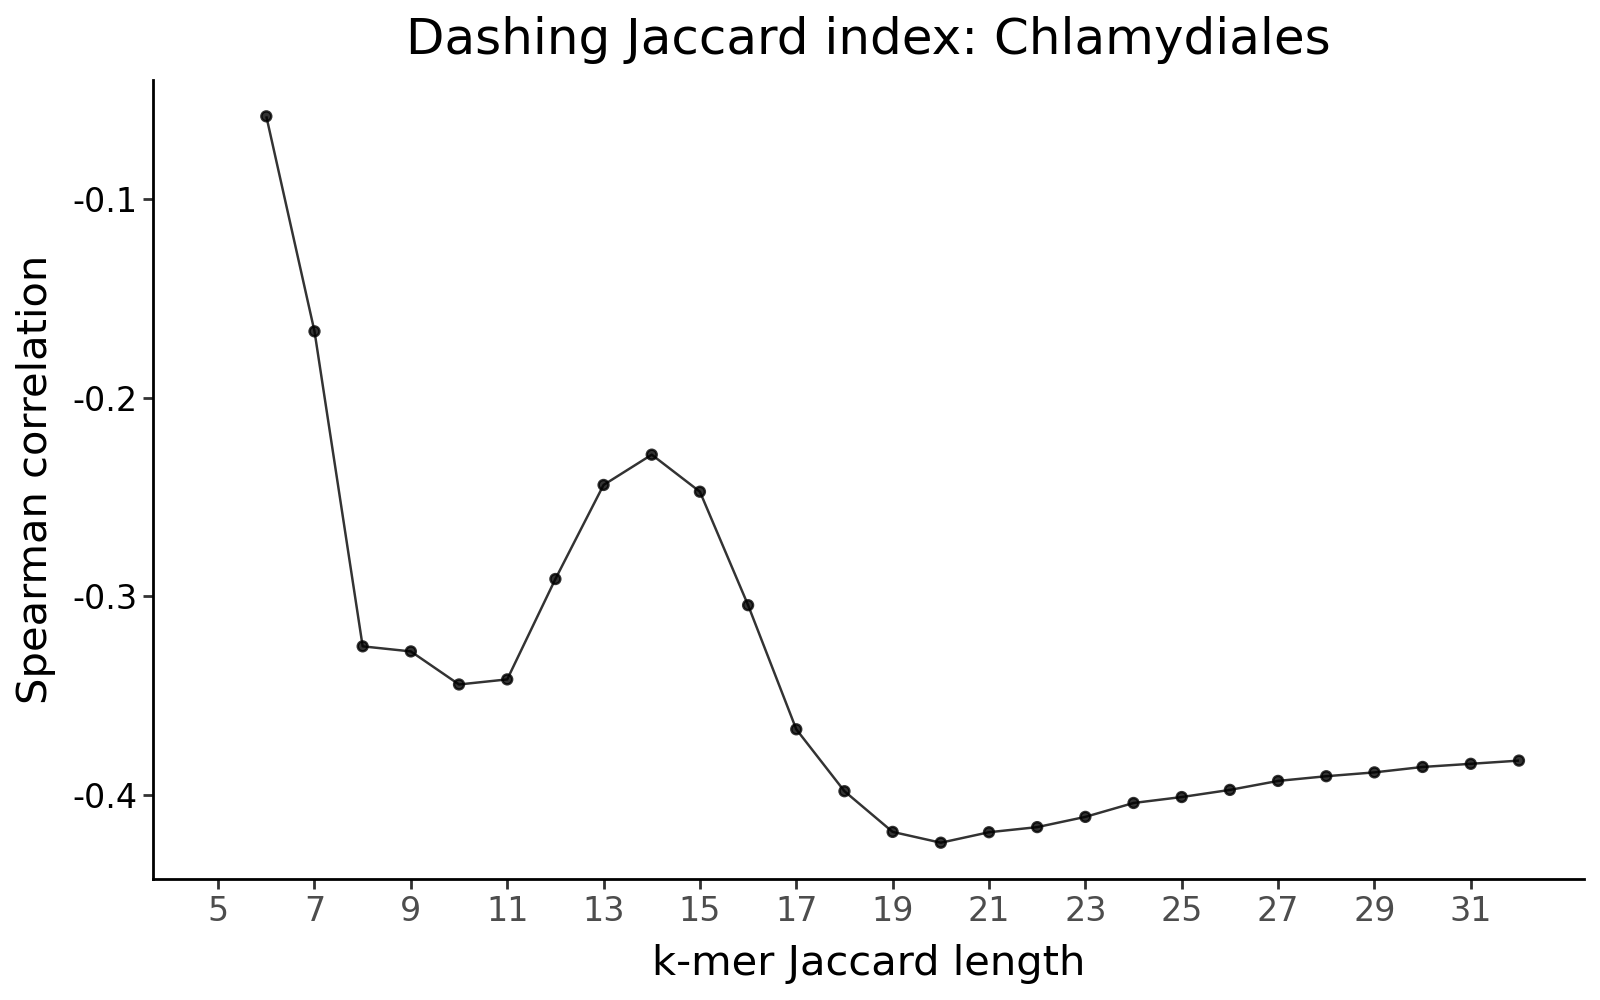

In [25]:
chlam_corr_df

(
    ggplot(chlam_corr_df) +
    geom_point(aes(x='k', y='spearman_corr'), alpha=0.8) +
    geom_line(aes(x='k', y='spearman_corr'), alpha=0.8) +
    # ggtitle("Dashing Jaccard index: Cyanobacteriales (n=585)") +
    ggtitle("Dashing Jaccard index: Chlamydiales") +
    xlab("k-mer Jaccard length") +
    ylab("Spearman correlation") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
    scale_x_continuous(breaks=range(5,33,2))
    # scale_x_continuous(breaks=range(5,33,2)) +
    # scale_color_manual(values=['#000000', '#D7263D'],  # Black, Royal blue, Green
                    #   breaks=['Single k', 'k and 20-mer'])  # Specify legend order
)

In [ ]:
# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df


In [ ]:

# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        try:
            k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        except Exception:
            k_val = fname

        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')

                # Fetch tree distance (symmetric)
                td = None
                if g1 in tree_dict and g2 in tree_dict[g1]:
                    td = tree_dict[g1][g2]
                elif g2 in tree_dict and g1 in tree_dict[g2]:
                    td = tree_dict[g2][g1]
                else:
                    continue  # skip pairs not present in the tree dict

                try:
                    dashing_dist = float(df.loc[raw1, raw2])
                except Exception:
                    # If labels aren't perfectly aligned, try the symmetric access
                    try:
                        dashing_dist = float(df.loc[raw2, raw1])
                    except Exception:
                        continue

                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        if len(x_dashing) >= 2:
            corr, pval = spearmanr(x_dashing, y_tree)
        else:
            corr, pval = np.nan, np.nan

        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)